# 01 Get SAROS data

**Before running:** upload two files into `MyDrive/ct-body-comp/raw/`:
1. SAROS Segmentations (NIfTI ZIP, ~87 MB), unzipped into a folder called `data`
2. Segmentation Information Spreadsheet (CSV)

Both are direct downloads on the TCIA SAROS page (Version 2): https://doi.org/10.25737/SZ96-ZG60

**Labels in body-regions.nii.gz:** 0 background, 1 subcutaneous tissue, 2 muscle, 3 abdominal cavity, 4 thoracic cavity, 5 bones, 6-13 small structures, **255 = unannotated slice (ignore)**. Only every 5th axial slice is annotated.

In [ ]:
# 1. Connect Google Drive so files survive after Colab shuts down
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/ct-body-comp'
RAW = f'{ROOT}/raw'
DATA = f'{RAW}/data'   # segmentations live here; CTs will be downloaded next to them

import os, glob
print('Segmentation cases found:', len(glob.glob(f'{DATA}/case_*')))
print('CSV files found:', glob.glob(f'{RAW}/*.csv'))

Mounted at /content/drive
Segmentation cases found: 900
CSV files found: ['/content/drive/MyDrive/ct-body-comp/raw/Segmentation-Info_09-29-2023.csv']


In [ ]:
!git clone -q https://github.com/UMEssen/saros-dataset /content/saros-dataset 2>/dev/null || echo 'repo already cloned'
%cd /content/saros-dataset
!pip -q install SimpleITK "pydicom<3"
!pip -q install --no-deps pydicom-seg
!python3 download.py --help | head -3

repo already cloned
/content/saros-dataset
usage: download.py [-h] [--info-csv INFO_CSV] [--target-dir TARGET_DIR]
                   [--save-original-image] [--save-meta-dicoms]
                   [--save-dicoms] [--force-download] [--no-login]


In [ ]:
# 3. Make a small subset CSV: skip restricted collections, keep the first N cases
import pandas as pd

N_CASES = 50   # start small; raise later
RESTRICTED = ['Head-Neck Cetuximab', 'ACRIN-HNSCC-FDG-PET/CT', 'QIN-HEADNECK',
              'TCGA-HNSC', 'HNSCC', 'Anti-PD-1_MELANOMA']

csv_path = [p for p in glob.glob(f'{RAW}/*.csv') if not p.endswith('saros_subset.csv')][0]
print('Using:', csv_path)
df = pd.read_csv(csv_path)
print(df.columns.tolist())

# A row is restricted if any cell mentions a restricted collection name
pattern = '|'.join(RESTRICTED).replace('(', r'\(').replace(')', r'\)')
is_restricted = df.astype(str).apply(lambda col: col.str.contains(pattern, regex=True)).any(axis=1)

subset = df[~is_restricted].head(N_CASES)
subset_path = f'{RAW}/saros_subset.csv'
subset.to_csv(subset_path, index=False)
print(f'Kept {len(subset)} of {len(df)} rows ({is_restricted.sum()} restricted skipped)')

Using: /content/drive/MyDrive/ct-body-comp/raw/Segmentation-Info_09-29-2023.csv
['id', 'tcia_study_instance_uid', 'tcia_series_instance_uid', 'tcia_collection', 'tcia_case_id', 'gender', 'anatomic_region', 'has_breast_implant', 'orientation_code', 'split']
Kept 50 of 900 rows (174 restricted skipped)


In [ ]:
# 4. Download the matching CTs from TCIA (resampled to 5 mm, saved as NIfTI next to the masks)
!python3 download.py --info-csv "{subset_path}" --target-dir "{DATA}" --no-login --parallel-downloads 2

Using the --no-login options downloads only publically available images. For full download please create a TCIA account and apply for the restricted collections used in SAROS.
/content/saros-dataset/download.py:361: UserWarning: 900 body regions and 809 body parts segmentations were found in the directory /content/drive/MyDrive/ct-body-comp/raw/data. There are supposed to be 900 of each. Please consider using the same directory as the segmentations you downloaded to ensure that the checks are run and that the segmentations are compatible with the downloaded images.
  warnings.warn(
  0% 0/50 [00:00<?, ?it/s]
case_000:   0% 0/5 [00:00<?, ?it/s]

case_001:   0% 0/5 [00:00<?, ?it/s]
case_000:  20% 1/5 [00:12<00:49, 12.29s/it]
case_000:  40% 2/5 [00:13<00:17,  5.72s/it]

case_001:  20% 1/5 [00:14<00:57, 14.35s/it]
case_000:  60% 3/5 [00:14<00:07,  3.83s/it]
case_000:  80% 4/5 [00:16<00:02,  2.85s/it]

case_001:  40% 2/5 [00:16<00:22,  7.35s/it]

case_001:  60% 3/5 [00:17<00:08,  4.26s/it]


/content/drive/MyDrive/ct-body-comp/raw/data/case_000
shape: (512, 512, 94) | voxel size (mm): (np.float32(0.78125), np.float32(0.78125), np.float32(5.0))
label values: [  0   1   2   3   4   5   7   9  11 255]
annotated slices: 20 of 94


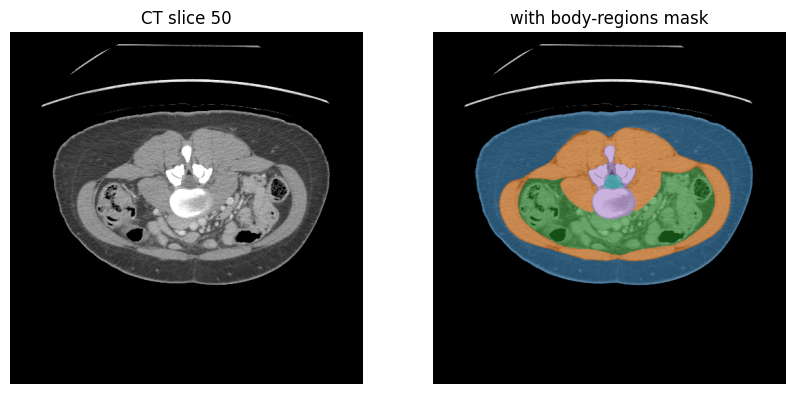

In [ ]:
# 5. Sanity check: load one case, list its labels, show a slice with the mask on top
import nibabel as nib, numpy as np, matplotlib.pyplot as plt

case = sorted(c for c in glob.glob(f'{DATA}/case_*') if os.path.exists(f'{c}/image.nii.gz'))[0]
ct = nib.load(f'{case}/image.nii.gz')
img = ct.get_fdata()
seg = nib.load(f'{case}/body-regions.nii.gz').get_fdata()

print(case)
print('shape:', img.shape, '| voxel size (mm):', ct.header.get_zooms())
print('label values:', np.unique(seg).astype(int))

LABELS = {1: 'subcutaneous', 2: 'muscle', 3: 'abdominal cavity', 4: 'thoracic cavity', 5: 'bones'}

# SAROS is sparse: unannotated slices are filled with 255. Keep slices with real labels.
annotated = [z for z in range(seg.shape[2]) if not (seg[:, :, z] == 255).all() and (seg[:, :, z] > 0).any()]
print(f'annotated slices: {len(annotated)} of {seg.shape[2]}')
z = annotated[len(annotated) // 2]

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.rot90(np.clip(img[:, :, z], -200, 250)), cmap='gray'); ax[0].set_title(f'CT slice {z}')
ax[1].imshow(np.rot90(np.clip(img[:, :, z], -200, 250)), cmap='gray')
ax[1].imshow(np.rot90(np.ma.masked_where((seg[:, :, z] == 0) | (seg[:, :, z] == 255), seg[:, :, z])), cmap='tab10', vmin=1, vmax=10, alpha=0.5); ax[1].set_title('with body-regions mask')
for a in ax: a.axis('off')
plt.show()